# step1_data_preprocess

**Owner:** P1  
**Purpose:** Shared preprocessing for MIND-large: chronological split (9–13 / 14 / 15 Nov), candidate-level rows, cold/warm labels from prior exposure counts, and 1:4 negative sampling on the fit split only.  
**Inputs:** `data/raw/MINDlarge_train/`, `data/raw/MINDlarge_dev/`  
**Outputs (`data/processed/`):**
- `fit_candidates_sampled.parquet`: training rows, 9–13 Nov, negative-sampled (every click + up to 4 unclicked articles per click from the same impression)
- `tune_candidates.parquet`: tuning rows, 14 Nov, full slates
- `eval_candidates.parquet`: final evaluation rows, 15 Nov (official dev), full slates
- `news_metadata.parquet`: article information (category, subcategory, title, abstract, entities, `news_idx`)
- `fit_impressions.parquet`, `tune_impressions.parquet`, `eval_impressions.parquet`: one row per impression with the user's click history


# Overview

The MIND-large training and development datasets are loaded and checked before preprocessing. Consistent integer indices are then created for users and news articles, while the original identifiers are retained for reference and metadata matching.

The labelled data is then split chronologically into model-fitting (9–13 Nov), tuning (14 Nov) and evaluation (15 Nov) periods. These splits by impressions are saved with the original `history` and `impressions` fields for models that need a user's click history.

Article exposure counts are tracked in chronological order to determine each candidate’s prior exposure count and corresponding cold/warm status. Negative sampling is subsequently applied to the fitting data only, while the tuning and evaluation sets retain their complete candidate slates.

The processed files are the shared inputs for our team's models:
- **Popularity and category-CTR baselines:** use the candidate files (labels, exposure counts, category)
- **Content-based filtering:** uses user click history and article title/abstract
- **NCF / NMF:** use the integer user and article indices
- **Feature-based MLP:** uses engineered features built from these files
- **NRMS (neural news model):** uses click history and article text
- **MMR re-ranking:** re-ranks the best model's scores, using category and the cold/warm label to measure diversity and fair exposure


> Runtime: Colab. Run all cells top to bottom; keep outputs saved.

In [12]:
# --- Setup: run this first, every session ---
from google.colab import drive
drive.mount('/content/drive')

!rm -rf /content/BT4222-Project-Group-4--MIND && git clone -q https://github.com/Fdiannz/BT4222-Project-Group-4--MIND.git /content/BT4222-Project-Group-4--MIND
import sys; sys.path.insert(0, '/content/BT4222-Project-Group-4--MIND')
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import config
from utils.data_utils import load_news, load_behaviors, split_by_date, negative_sample
from utils.metrics import evaluate, evaluate_by_segment, topk, topk_diversity
print("Data folder:", config.DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data folder: /content/drive/MyDrive/BT4222_Project/data


## 1A. Load MIND-large Data: news and behaviors
(uses the shared `load_news` and `load_behaviors`; `load_news` handles the quote-parsing issue)

Load the official MIND-large **training** (9–14 Nov) and **development** (15 Nov) files. The official test split is not loaded because it has no click labels, so no metric can be computed on it.
- `behaviors.tsv` contains impression sessions: impression ID, user ID, timestamp, the user's click history, and the candidate article slate with click labels
- `news.tsv` contains article metadata: category, subcategory, title, abstract, URL and entity information

The files are then checked for duplicate rows, missing values and blank fields.

In [13]:
# Set folder paths - raw input and processed output
RAW_DIR = Path(config.DATA_DIR) / "raw"
PROCESSED_DIR = Path(config.DATA_DIR) / "processed"

TRAIN_DIR = RAW_DIR / "MINDlarge_train"
DEV_DIR   = RAW_DIR / "MINDlarge_dev"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
print("Processed folder:", PROCESSED_DIR)

# Load impression logs (user, time, click history, articles shown)
train_beh = load_behaviors(TRAIN_DIR / "behaviors.tsv")
dev_beh   = load_behaviors(DEV_DIR / "behaviors.tsv")

# Load article metadata (category, title, abstract, entities)
train_news = load_news(TRAIN_DIR / "news.tsv")
dev_news   = load_news(DEV_DIR / "news.tsv")

# Shape, size and date range of data
print("Training behaviours:", train_beh.shape)
print("Development behaviours:", dev_beh.shape)
print("Training news:", train_news.shape)
print("Development news:", dev_news.shape)

print("Training period:", train_beh["time"].min(), "to", train_beh["time"].max())
print("Development period:", dev_beh["time"].min(), "to", dev_beh["time"].max())


Processed folder: /content/drive/MyDrive/BT4222_Project/data/processed
Training behaviours: (2232748, 5)
Development behaviours: (376471, 5)
Training news: (101527, 8)
Development news: (72023, 8)
Training period: 2019-11-09 00:00:00 to 2019-11-14 23:59:59
Development period: 2019-11-15 00:00:00 to 2019-11-15 23:59:43


In [4]:
#Check duplicate and missing values for behaviour.tsv (All 0)
print("Duplicate training behaviour rows:", train_beh.duplicated().sum())
print("Duplicate development behaviour rows:", dev_beh.duplicated().sum())

print("\nTraining behaviour missing values:")
print(train_beh.isnull().sum())
print("\nDevelopment behaviour missing values:")
print(dev_beh.isnull().sum())

#Check duplicate and missing values for news.tsv (All 0)
print("Duplicate training news rows:", train_news.duplicated().sum())
print("Duplicate development news rows:", dev_news.duplicated().sum())

print("\nTraining news missing values:")
print(train_news.isnull().sum())
print("\nDevelopment news missing values:")
print(dev_news.isnull().sum())

# Check blank fields
print("Blank training histories:",
      (train_beh["history"] == "").sum())

print("\nBlank fields in training news:")
for col in ["title", "abstract", "title_entities", "abstract_entities"]:
    print(col, ":", (train_news[col] == "").sum())

print("\nBlank fields in development news:")
for col in ["title", "abstract", "title_entities", "abstract_entities"]:
    print(col, ":", (dev_news[col] == "").sum())

Duplicate training behaviour rows: 0
Duplicate development behaviour rows: 0

Training behaviour missing values:
impression_id    0
user_id          0
time             0
history          0
impressions      0
dtype: int64

Development behaviour missing values:
impression_id    0
user_id          0
time             0
history          0
impressions      0
dtype: int64
Duplicate training news rows: 0
Duplicate development news rows: 0

Training news missing values:
news_id              0
category             0
subcategory          0
title                0
abstract             0
url                  0
title_entities       0
abstract_entities    0
dtype: int64

Development news missing values:
news_id              0
category             0
subcategory          0
title                0
abstract             0
url                  0
title_entities       0
abstract_entities    0
dtype: int64
Blank training histories: 46065

Blank fields in training news:
title : 0
abstract : 5415
title_entities :

## 1B. Data Analysis: Why the Preprocessing Steps Are Needed

Before preprocessing, we check properties of the data that determine how it must be prepared:

(a) clicks are rare, negative sampling will be needed for training

(b) the articles shown change daily, a chronological split and cold/warm labels will be needed.

In [21]:
# 1B(a). Daily volume and click imbalance
daily_rows = []
for source, beh in [("train", train_beh), ("dev", dev_beh)]:
    # Count articles shown and clicks per impression ("-1" = clicked)
    displays = beh["impressions"].str.count(" ") + 1
    clicks = beh["impressions"].str.count("-1")
    # Total per day and label each day with its split
    g = pd.DataFrame({"date": beh["time"].dt.date, "displays": displays, "clicks": clicks}).groupby("date")
    d = g.agg(impressions=("displays", "size"), displays=("displays", "sum"), clicks=("clicks", "sum"))
    d["split"] = "eval" if source == "dev" else np.where(d.index.astype(str) <= config.FIT_DATES[1], "fit", "tune")
    daily_rows.append(d)
daily = pd.concat(daily_rows)
daily.index = pd.to_datetime(daily.index).strftime("%a %d Nov")

# Add a total row, then non-clicks, CTR and imbalance
daily.loc["Total"] = [daily.impressions.sum(), daily.displays.sum(), daily.clicks.sum(), "all"]
daily[["impressions", "displays", "clicks"]] = daily[["impressions", "displays", "clicks"]].astype("int64")
daily["non-clicks"] = daily.displays - daily.clicks
daily["CTR %"] = (100 * daily.clicks / daily.displays).astype(float).round(2)
daily["non-clicks per click"] = (daily["non-clicks"] / daily.clicks).astype(float).round(1)

cols = ["split", "impressions", "displays", "clicks", "non-clicks", "CTR %", "non-clicks per click"]
display(daily[cols].style.format({c: "{:,}" for c in ["impressions", "displays", "clicks", "non-clicks"]}
                                 | {"CTR %": "{:.2f}", "non-clicks per click": "{:.1f}"}))
t = daily.loc["Total"]
print(f"Total clicks:      {t.clicks:,}")
print(f"Total non-clicks:  {t['non-clicks']:,}")
print(f"Imbalance: about 1 click for every {t['non-clicks per click']} non-clicks")
print("-> Negative sampling is needed for training (Section 6)")


,split,impressions,displays,clicks,non-clicks,CTR %,non-clicks per click
date,,,,,,,
Sat 09 Nov,fit,"192,552","7,544,547","290,054","7,254,493",3.84,25.0
Sun 10 Nov,fit,"212,343","7,496,213","311,416","7,184,797",4.15,23.1
Mon 11 Nov,fit,"464,467","16,583,216","683,491","15,899,725",4.12,23.3
Tue 12 Nov,fit,"478,375","16,744,834","734,806","16,010,028",4.39,21.8
Wed 13 Nov,fit,"453,494","17,738,458","692,845","17,045,613",3.91,24.6
Thu 14 Nov,tune,"431,517","17,400,106","671,044","16,729,062",3.86,24.9
Fri 15 Nov,eval,"376,471","14,085,557","574,845","13,510,712",4.08,23.5
Total,all,"2,609,219","97,592,931","3,958,501","93,634,430",4.06,23.7


Total clicks:      3,958,501
Total non-clicks:  93,634,430
Imbalance: about 1 click for every 23.7 non-clicks
-> Negative sampling is needed for training (Section 6)


Clicks are rare. Across all 7 days, users clicked 3,958,501 of 97,592,931 displayed articles (CTR 4.06%), about **1 click for every 23.7 non-clicks**. The daily CTR stays between 3.84% and 4.39%, so the tuning (14 Nov) and evaluation (15 Nov) days are representative of the fitting period. Weekend traffic (192,552 and 212,343 impressions) is less than half of weekday traffic (431,517–478,375). Because clicks are so rare, the fitting set is negative-sampled to up to 4 non-clicks per click (Section 6), while tuning and evaluation keep their full slates.

,articles shown,new articles,seen before,% new
date,,,,
Sat 09 Nov,6988,6988,0,100.0
Sun 10 Nov,7421,3111,4310,41.9
Mon 11 Nov,9640,4544,5096,47.1
Tue 12 Nov,9220,4205,5015,45.6
Wed 13 Nov,9952,4443,5509,44.6
Thu 14 Nov,9107,3755,5352,41.2
Fri 15 Nov,6997,2263,4734,32.3


On 15 Nov, 2,263 of 6,997 articles shown (32.3%) had never been shown during 9–14 Nov.
-> The split must be chronological, and new articles need cold/warm labels (Section 5).


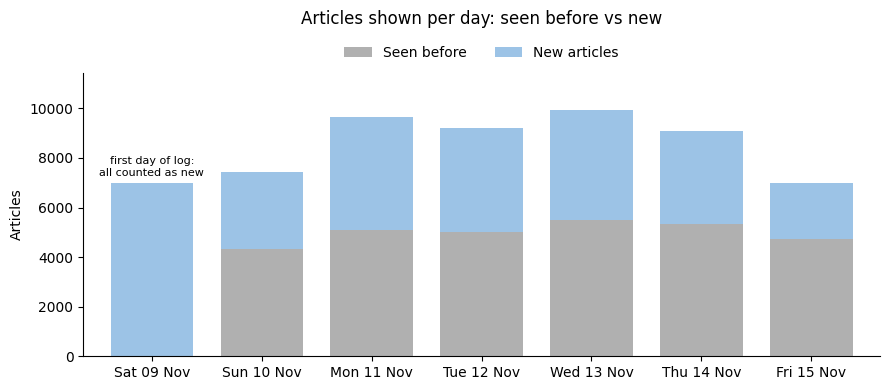

In [22]:
# 1B(b). Articles change daily -> chronological split and cold/warm labels
import matplotlib.pyplot as plt

seen, turnover = set(), []
for beh in [train_beh, dev_beh]:
    for day, g in beh.groupby(beh["time"].dt.date):
        # Articles shown today (click labels removed), and which were never shown before
        shown = set(" ".join(g["impressions"]).replace("-0", "").replace("-1", "").split())
        new = shown - seen
        turnover.append({"date": pd.Timestamp(day).strftime("%a %d Nov"),
                         "articles shown": len(shown), "new articles": len(new),
                         "seen before": len(shown) - len(new),
                         "% new": round(100 * len(new) / len(shown), 1)})
        seen |= shown
turnover = pd.DataFrame(turnover).set_index("date")
display(turnover)

# Key numbers for the evaluation day (15 Nov)
ev = turnover.iloc[-1]
print(f"On 15 Nov, {int(ev['new articles']):,} of {int(ev['articles shown']):,} articles shown ({ev['% new']}%) "
      f"had never been shown during 9–14 Nov.")
print("-> The split must be chronological, and new articles need cold/warm labels (Section 5).")

# Chart: articles seen before vs new, per day
fig, ax = plt.subplots(figsize=(9, 4), facecolor="white")
turnover[["seen before", "new articles"]].plot(kind="bar", stacked=True, ax=ax, width=0.75,
                                               color=["#B0B0B0", "#9CC3E6"])
ax.set_facecolor("white")
ax.set_title("Articles shown per day: seen before vs new", pad=35)
ax.set_xlabel(""); ax.set_ylabel("Articles")
ax.tick_params(axis="x", rotation=0)
ax.set_ylim(0, turnover["articles shown"].max() * 1.15)
ax.legend(["Seen before", "New articles"], loc="lower center", bbox_to_anchor=(0.5, 1.0),
          ncol=2, frameon=False)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.text(0, turnover["articles shown"].iloc[0] * 1.03, "first day of log:\nall counted as new",
        ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

Articles change every day. From 10 November onwards, 3,111–4,544 articles appear for the first time each day (32–47% of the articles shown). On 15 November, **2,263 of the 6,997 articles shown (32.3%) had never been shown during 9–14 November**. (9 November counts every article as new only because the log starts that day.) The split must therefore be chronological, so that models never see an article's future clicks, and each displayed article needs a cold/warm label (Section 5) so models can be evaluated separately on new articles.

## 2. Create Shared User and Article ID Mappings
MIND stores users and articles using string IDs such as `U13740` and `N12345`. Some embedding-based models: NCF/NMF require these IDs to be represented as integers.

This step creates:
- `user_id` → `user_idx`
- `news_id` → `news_idx`
The original IDs are kept for metadata joins, exposure tracking and checking results.

For users, the mapping is created from the official training file (9–14 Nov). Any user appearing for the first time in the development set (15 Nov) is mapped to `0`, representing an unknown user. Note that users who first appear on 14 Nov (tuning) also receive an index, although a model fitted on 9–13 Nov has not seen them.

For articles, training and development metadata are combined because development may contain newly introduced articles that still need content representations during evaluation. No click information from the development set is used here.

Index `0` is reserved for unknown or padding values.

In [24]:
# For User mapping
# Build user mapping from training data only
train_users = train_beh["user_id"].drop_duplicates().reset_index(drop=True)

user_map = pd.DataFrame({"user_id": train_users})

# Start from 1; reserve 0 for unseen/unknown users
user_map["user_idx"] = np.arange(1, len(user_map) + 1, dtype=np.int32)
user2idx = dict(zip(user_map["user_id"], user_map["user_idx"]))

# Apply user mapping
train_beh["user_idx"] = (train_beh["user_id"].map(user2idx).fillna(0).astype("int32"))

dev_beh["user_idx"] = (dev_beh["user_id"].map(user2idx).fillna(0).astype("int32"))



# For Article mapping
# Combine article metadata so development-only articles can still be represented
news_meta = pd.concat([train_news, dev_news], ignore_index=True)

news_meta = (news_meta.drop_duplicates(subset="news_id", keep="first").reset_index(drop=True))

# Start from 1; reserve 0 for unknown/padding
news_meta["news_idx"] = np.arange(1, len(news_meta) + 1, dtype=np.int32)

news2idx = dict(zip(news_meta["news_id"], news_meta["news_idx"]))

# Add article indices back to train/dev metadata
train_news["news_idx"] = (train_news["news_id"].map(news2idx).fillna(0).astype("int32"))

dev_news["news_idx"] = (dev_news["news_id"].map(news2idx).fillna(0).astype("int32"))

# Save shared mappings
news_meta.to_parquet(PROCESSED_DIR / "news_metadata.parquet", index=False)

# Checks
print("Mapped training users:", len(user2idx))
print("Mapped articles:", len(news2idx))
print("Development rows with unseen users:",(dev_beh["user_idx"] == 0).sum())
unseen_dev_users = dev_beh.loc[dev_beh["user_idx"] == 0, "user_id"].nunique()
print("Unique unseen development users:", unseen_dev_users)

# Show all columns when displaying tables
pd.set_option("display.max_columns", None)

# Behaviour table with the new user_idx column
print("\nTraining behaviours (first 5 rows):")
display(train_beh.head())

print("\nDevelopment behaviours (first 5 rows):")
display(dev_beh.head())

# Article table with the new news_idx column
print("\nArticle metadata (first 5 rows):")
display(news_meta.head())

Mapped training users: 711222
Mapped articles: 104151
Development rows with unseen users: 48610
Unique unseen development users: 39212

Training behaviours (first 5 rows):


,impression_id,user_id,time,history,impressions,user_idx
0,1,U87243,2019-11-10 11:30:54,N8668 N39081 N65259 N79529 N73408 N43615 N2937...,N78206-0 N26368-0 N7578-0 N58592-0 N19858-0 N5...,1
1,2,U598644,2019-11-12 13:45:29,N56056 N8726 N70353 N67998 N83823 N111108 N107...,N47996-0 N82719-0 N117066-0 N8491-0 N123784-0 ...,2
2,3,U532401,2019-11-13 11:23:03,N128643 N87446 N122948 N9375 N82348 N129412 N5...,N103852-0 N53474-0 N127836-0 N47925-1,3
3,4,U593596,2019-11-12 12:24:09,N31043 N39592 N4104 N8223 N114581 N92747 N1207...,N38902-0 N76434-0 N71593-0 N100073-0 N108736-0...,4
4,5,U239687,2019-11-14 20:03:01,N65250 N122359 N71723 N53796 N41663 N41484 N11...,N76209-0 N48841-0 N67937-0 N62235-0 N6307-0 N3...,5



Development behaviours (first 5 rows):


,impression_id,user_id,time,history,impressions,user_idx
0,1,U134050,2019-11-15 08:55:22,N12246 N128820 N119226 N4065 N67770 N33446 N10...,N91737-0 N30206-0 N54368-0 N117802-0 N18190-0 ...,89712
1,2,U254959,2019-11-15 11:42:35,N34011 N9375 N67397 N7936 N118985 N109453 N103...,N119999-0 N24958-0 N104054-0 N33901-0 N9250-0 ...,516861
2,3,U499841,2019-11-15 09:08:21,N63858 N26834 N6379 N85484 N15229 N65119 N1047...,N18190-0 N89764-0 N91737-0 N54368-0 N49978-1 N...,209744
3,4,U107107,2019-11-15 05:50:31,N12959 N8085 N18389 N3758 N9740 N90543 N129790...,N122944-1 N18190-0 N55801-0 N59297-0 N128045-0...,445267
4,5,U492344,2019-11-15 05:02:25,N109183 N48453 N85005 N45706 N98923 N46069 N35...,N64785-0 N82503-0 N32993-0 N122944-0 N29160-0 ...,541225



Article metadata (first 5 rows):


,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities,news_idx
0,N88753,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the...",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"",...",[],1
1,N45436,news,newsscienceandtechnology,Walmart Slashes Prices on Last-Generation iPads,Apple's new iPad releases bring big deals on l...,https://assets.msn.com/labs/mind/AABmf2I.html,"[{""Label"": ""IPad"", ""Type"": ""J"", ""WikidataId"": ...","[{""Label"": ""IPad"", ""Type"": ""J"", ""WikidataId"": ...",2
2,N23144,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik...","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik...",3
3,N86255,health,medical,Dispose of unwanted prescription drugs during ...,,https://assets.msn.com/labs/mind/AAISxPN.html,"[{""Label"": ""Drug Enforcement Administration"", ...",[],4
4,N93187,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId...",5


From `behaviors.tsv`, there are **711,222 unique users** in the training data (9–14 Nov), each mapped to a unique index from 1 to 711,222. The training data contains 2,232,748 impressions because many users visit more than once; all impressions from the same user share the same `user_idx`.

From `news.tsv`, there are **104,151 unique articles** across the training and development files, each mapped to a unique index from 1 to 104,151. Development articles are included so that new articles on 15 Nov still have an index and content features.

In the development data (15 Nov), **48,610 of the 376,471 impressions (12.9%)** come from users who never appeared during 9–14 Nov. These impressions belong to **39,212 unique new users**. Some visited more than once and are assigned `user_idx = 0` (unknown user). This is the **user cold-start** problem: models that learn a separate representation for each user (NCF/NMF) have no information about these users, whereas models based on click history and article content can still score them.

## 3. Create Chronological Modelling Splits (Training Dataset)

To preserve the temporal order of user interactions and avoid future-information
leakage, the official MIND-large training set is divided chronologically.
Sessions from 9–13 November are used for model fitting, while 14 November is
reserved for tuning. The official development set on 15 November is kept as the
final labelled evaluation set.

In [26]:
# Split training data into fit and tuning periods
fit_beh, tune_beh = split_by_date(
    train_beh,
    fit_dates=("2019-11-09", "2019-11-13"),
    tune_date="2019-11-14"
)

# Use official development data as final labelled evaluation set
eval_beh = dev_beh.copy()

# Checks
print("Fit period:", fit_beh["time"].min(), "to", fit_beh["time"].max())
print("Tune period:", tune_beh["time"].min(), "to", tune_beh["time"].max())
print("Evaluation period:", eval_beh["time"].min(), "to", eval_beh["time"].max())

print("\nFit impressions:", len(fit_beh))
print("Tune impressions:", len(tune_beh))
print("Evaluation impressions:", len(eval_beh))

Fit period: 2019-11-09 00:00:00 to 2019-11-13 23:59:57
Tune period: 2019-11-14 00:00:00 to 2019-11-14 23:59:59
Evaluation period: 2019-11-15 00:00:00 to 2019-11-15 23:59:43

Fit impressions: 1801231
Tune impressions: 431517
Evaluation impressions: 376471


## 4. Save Impression-Level Splits
The three chronological splits are saved in their **original `behaviors.tsv` format**: one row per impression, with the same columns as the raw file (`impression_id`, `user_id`, `time`, `history`, `impressions`) with the new column `user_idx`. Only splitted by date:
- `fit_impressions.parquet`: original training data from 9–13 Nov
- `tune_impressions.parquet`: original training data from 14 Nov
- `eval_impressions.parquet`: original development data (15 Nov)

This is useful because personalised models may need the original history field. Saving it once at impression level avoids repeating the same long user history for every candidate article, which would make the candidate datasets unnecessarily large.

In [27]:
fit_beh.to_parquet(PROCESSED_DIR / "fit_impressions.parquet", index=False)
tune_beh.to_parquet(PROCESSED_DIR / "tune_impressions.parquet", index=False)
eval_beh.to_parquet(PROCESSED_DIR / "eval_impressions.parquet", index=False)

print("Saved fit impressions:", len(fit_beh))
print("Saved tune impressions:", len(tune_beh))
print("Saved evaluation impressions:", len(eval_beh))

Saved fit impressions: 1801231
Saved tune impressions: 431517
Saved evaluation impressions: 376471


## 5. Calculate Prior Article Exposure and Cold/Warm Status

For each article, track how many times it has appeared in candidate impressions before the current impression.
- Articles with fewer than 10 prior exposures are labelled cold
- Articles with 10 or more prior exposures are labelled warm
- Exposure counts are updated chronologically so that only earlier impressions contribute to the current article’s exposure history

In [29]:
from collections import Counter
import pyarrow as pa
import pyarrow.parquet as pq

# Lookups: article -> category / subcategory (added to every candidate row)
news_to_category = dict(zip(news_meta["news_id"], news_meta["category"]))
news_to_subcategory = dict(zip(news_meta["news_id"], news_meta["subcategory"]))

def process_exposure_labels(beh, starting_counts, output_path, chunk_size=500000):
    # Start from the exposure counts of all earlier periods
    counts = starting_counts.copy()

    # Go through impressions in time order
    beh = beh.sort_values(["time", "impression_id"], kind="stable")
    rows, writer = [], None

    for row in beh.itertuples(index=False):
        # Split "N1-0 N2-1" into [("N1", "0"), ("N2", "1")]
        candidates = [item.rsplit("-", 1) for item in row.impressions.split()]

        # One row per article shown: record its count BEFORE this impression
        for news_id, label in candidates:
            prior_count = counts[news_id]
            rows.append({
                "impression_id": row.impression_id,
                "user_id": row.user_id,
                "user_idx": row.user_idx,
                "time": row.time,
                "news_id": news_id,
                "news_idx": news2idx.get(news_id, 0),
                "label": int(label),                          # 1 = clicked, 0 = not clicked
                "prior_exposure_count": prior_count,
                "cold_article": int(prior_count < 10),        # cold if shown < 10 times before
                "category": news_to_category.get(news_id, "unknown"),
                "subcategory": news_to_subcategory.get(news_id, "unknown")
            })

        # Only now add this impression's displays to the counts (no future information)
        for news_id, _ in candidates:
            counts[news_id] += 1

        # Write to disk every 500,000 rows to save memory
        if len(rows) >= chunk_size:
            table = pa.Table.from_pandas(pd.DataFrame(rows), preserve_index=False)
            if writer is None:
                writer = pq.ParquetWriter(str(output_path), table.schema, compression="snappy")
            writer.write_table(table)
            rows = []

    # Write the remaining rows and close the file
    if rows:
        table = pa.Table.from_pandas(pd.DataFrame(rows), preserve_index=False)
        if writer is None:
            writer = pq.ParquetWriter(str(output_path), table.schema, compression="snappy")
        writer.write_table(table)
    if writer is not None:
        writer.close()

    # Return the updated counts so the next split can continue from them
    return counts


# Starting counts for tuning: every display during 9–13 Nov
prior_exposure = Counter()
for impression in fit_beh["impressions"]:
    for item in impression.split():
        news_id = item.rsplit("-", 1)[0]
        prior_exposure[news_id] += 1

# Checks
print("Articles with exposure history:", len(prior_exposure))
print("Total candidate exposures:", sum(prior_exposure.values()))

Articles with exposure history: 23291
Total candidate exposures: 66107268


## 5B. Process Tuning and Evaluation Candidates

The 14 November tuning set starts with the exposure history accumulated from 9–13 November. For every candidate shown on 14 November, its prior_exposure_count is recorded before the current impression is added to the history.

The resulting counts are then carried forward into the 15 November evaluation set. This ensures that cold/warm status always uses only information from earlier impressions, consistent with the project definition.

The complete candidate slates are retained for both tuning and evaluation.

In [33]:
# ---------------------------------
# 5B. Process tuning and evaluation candidates
# ---------------------------------

# Process 14 Nov tuning candidates
tune_output = PROCESSED_DIR / "tune_candidates.parquet"

counts_after_tune = process_exposure_labels(
    tune_beh,
    prior_exposure,
    tune_output
)

# Process 15 Nov evaluation candidates
eval_output = PROCESSED_DIR / "eval_candidates.parquet"

counts_after_eval = process_exposure_labels(
    eval_beh,
    counts_after_tune,
    eval_output
)

# Checks
print("Articles tracked after 14 Nov:", len(counts_after_tune))
print("Articles tracked after 15 Nov:", len(counts_after_eval))

print("\nSaved tuning candidates:", tune_output)
print("Saved evaluation candidates:", eval_output)

# Display sample tuning rows
pf_tune = pq.ParquetFile(tune_output)
tune_sample = pf_tune.read_row_group(0).to_pandas()

display(tune_sample.head(10))

Articles tracked after 14 Nov: 27046
Articles tracked after 15 Nov: 29309

Saved tuning candidates: /content/drive/MyDrive/BT4222_Project/data/processed/tune_candidates.parquet
Saved evaluation candidates: /content/drive/MyDrive/BT4222_Project/data/processed/eval_candidates.parquet


,impression_id,user_id,user_idx,time,news_id,news_idx,label,prior_exposure_count,cold_article,category,subcategory
0,612270,U282205,378386,2019-11-14,N123683,91826,0,51422,0,lifestyle,lifestyleroyals
1,612270,U282205,378386,2019-11-14,N108269,81036,0,17845,0,news,newsworld
2,612270,U282205,378386,2019-11-14,N120332,78309,0,594,0,news,newscrime
3,612270,U282205,378386,2019-11-14,N18405,91279,0,21845,0,news,newsgoodnews
4,612270,U282205,378386,2019-11-14,N51569,88529,0,42683,0,entertainment,celebrity
5,612270,U282205,378386,2019-11-14,N17232,91980,0,2701,0,video,science
6,612270,U282205,378386,2019-11-14,N39403,74466,0,92283,0,entertainment,celebrity
7,612270,U282205,378386,2019-11-14,N108057,92379,0,4398,0,news,newscrime
8,612270,U282205,378386,2019-11-14,N87315,96416,0,5529,0,video,animals
9,612270,U282205,378386,2019-11-14,N64129,78066,0,1253,0,news,newsus


In [34]:
#Check on cold/warm
cold_count = 0
warm_count = 0

for i in range(pf_tune.num_row_groups):

    chunk = pf_tune.read_row_group(i, columns=["cold_article"]).to_pandas()

    cold_count += (chunk["cold_article"] == 1).sum()
    warm_count += (chunk["cold_article"] == 0).sum()

total_count = cold_count + warm_count

print("Cold candidate exposures:", cold_count)
print("Warm candidate exposures:", warm_count)
print("Cold share:", cold_count / total_count)

Cold candidate exposures: 35754
Warm candidate exposures: 17364352
Cold share: 0.0020548150683679742


,displays,cold displays,cold % of displays,clicks,cold clicks,cold % of clicks,articles shown,articles cold at some point
split,,,,,,,,
Tune (14 Nov),"17,400,106","35,754",0.210000,"671,044","1,679",0.250000,"9,107","4,784"
Eval (15 Nov),"14,085,557","22,465",0.160000,"574,845","1,113",0.190000,"6,997","3,030"


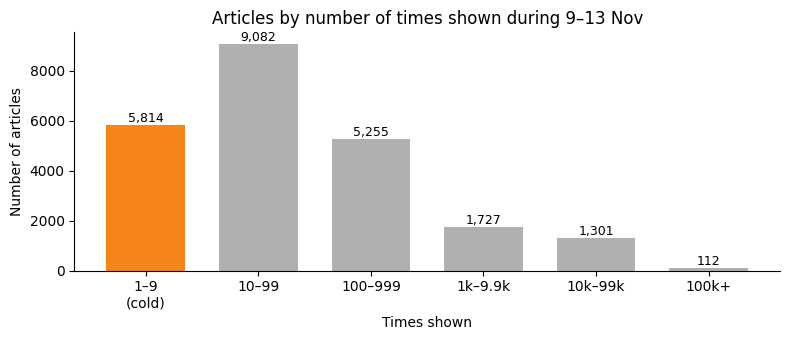

5,814 of 23,291 articles (25.0%) were shown fewer than 10 times during 9–13 Nov; the median article was shown 45 times.


In [35]:
# 5C. Summary of exposure counts and cold/warm labels
import matplotlib.pyplot as plt

# Table: cold vs warm per split (rows = displays, clicks = clicked displays)
summary = []
for name, path in [("Tune (14 Nov)", tune_output), ("Eval (15 Nov)", eval_output)]:
    c = pd.read_parquet(path, columns=["news_id", "label", "cold_article"])
    clicked = c["label"] == 1
    summary.append({
        "split": name,
        "displays": len(c),
        "cold displays": int(c["cold_article"].sum()),
        "cold % of displays": round(100 * c["cold_article"].mean(), 2),
        "clicks": int(clicked.sum()),
        "cold clicks": int(c.loc[clicked, "cold_article"].sum()),
        "cold % of clicks": round(100 * c.loc[clicked, "cold_article"].mean(), 2),
        "articles shown": c["news_id"].nunique(),
        "articles cold at some point": c.loc[c["cold_article"] == 1, "news_id"].nunique(),
    })
    del c
summary = pd.DataFrame(summary).set_index("split")
display(summary.style.format({c: "{:,}" for c in summary.columns if "%" not in c}))

# Chart: how often each article was shown during 9–13 Nov (threshold = 10)
exposures = pd.Series(prior_exposure)
bins = [1, 10, 100, 1_000, 10_000, 100_000, exposures.max() + 1]
labels = ["1–9\n(cold)", "10–99", "100–999", "1k–9.9k", "10k–99k", "100k+"]
binned = pd.cut(exposures, bins=bins, right=False, labels=labels).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5), facecolor="white")
ax.bar(binned.index.astype(str), binned.values, color=["#F58518"] + ["#B0B0B0"] * (len(binned) - 1), width=0.7)
for x, v in zip(binned.index.astype(str), binned.values):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Articles by number of times shown during 9–13 Nov")
ax.set_xlabel("Times shown"); ax.set_ylabel("Number of articles")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()
print(f"{(exposures < 10).sum():,} of {len(exposures):,} articles ({(exposures < 10).mean():.1%}) "
      f"were shown fewer than 10 times during 9–13 Nov; the median article was shown {int(exposures.median()):,} times.")

During 9–13 Nov, the median article was shown 45 times, and 5,814 of 23,291 articles (25.0%) were shown fewer than 10 times. On 14 and 15 Nov, many articles are cold at some point (4,784 and 3,030 articles), yet cold rows make up only 0.21% and 0.16% of displays. Each new article is cold only for its first 10 displays, which pass within minutes because of the high traffic.

## 6. Expand Impressions and Negative-Sample the Fit Split Only

The fitting data from 9–13 November is converted to candidate-level rows and prepared for model training.

Because the fitting set is highly imbalanced, all clicked candidates are retained while up to four displayed-but-unclicked candidates are sampled per click from the same impression. (1:4 unclicked)

Cold/warm status must be calculated before sampling, using the complete original impression slate. Tuning and evaluation data are not sampled because their complete candidate slates are required for ranking evaluation.

In [37]:
from utils.data_utils import negative_sample

def process_fit_candidates(beh, output_path, chunk_size=500000, neg_per_pos=4, seed=42):
    # Exposure counts start at 0 on 9 Nov (first day of the log)
    counts = Counter()

    # Go through impressions in time order
    beh = beh.sort_values(["time", "impression_id"], kind="stable")
    rows, writer, chunk_number = [], None, 0

    for row in beh.itertuples(index=False):
        # Split "N1-0 N2-1" into [("N1", "0"), ("N2", "1")]
        candidates = [item.rsplit("-", 1) for item in row.impressions.split()]

        # One row per article shown, with its count BEFORE this impression
        for news_id, label in candidates:
            prior_count = counts[news_id]
            rows.append({
                "impression_id": row.impression_id,
                "user_id": row.user_id,
                "user_idx": row.user_idx,
                "time": row.time,
                "news_id": news_id,
                "news_idx": news2idx.get(news_id, 0),
                "label": int(label),
                "prior_exposure_count": prior_count,
                "cold_article": int(prior_count < 10),
                "category": news_to_category.get(news_id, "unknown"),
                "subcategory": news_to_subcategory.get(news_id, "unknown")
            })

        # Update counts using the FULL slate (all displays, clicked or not)
        for news_id, _ in candidates:
            counts[news_id] += 1

        # Every 500,000 rows: negative-sample, then write to disk
        # (only after a whole impression, so slates are never split)
        if len(rows) >= chunk_size:
            chunk_df = negative_sample(pd.DataFrame(rows), neg_per_pos=neg_per_pos,
                                       seed=seed + chunk_number)   # keep all clicks + up to 4 non-clicks each
            table = pa.Table.from_pandas(chunk_df, preserve_index=False)
            if writer is None:
                writer = pq.ParquetWriter(str(output_path), table.schema, compression="snappy")
            writer.write_table(table)
            rows, chunk_number = [], chunk_number + 1

    # Sample and write the remaining rows, then close the file
    if rows:
        chunk_df = negative_sample(pd.DataFrame(rows), neg_per_pos=neg_per_pos, seed=seed + chunk_number)
        table = pa.Table.from_pandas(chunk_df, preserve_index=False)
        if writer is None:
            writer = pq.ParquetWriter(str(output_path), table.schema, compression="snappy")
        writer.write_table(table)
    if writer is not None:
        writer.close()

    # Counts after 13 Nov
    return counts

In [38]:
fit_output = PROCESSED_DIR / "fit_candidates_sampled.parquet"

counts_after_fit = process_fit_candidates(
    fit_beh,
    fit_output,
    neg_per_pos=4,
    seed=42
)

print("Saved fitting candidates:", fit_output)
print("Articles tracked after 13 Nov:", len(counts_after_fit))

Saved fitting candidates: /content/drive/MyDrive/BT4222_Project/data/processed/fit_candidates_sampled.parquet
Articles tracked after 13 Nov: 23291


## 7. Validate Final Processed Splits
Checks that the saved fitting, tuning and evaluation files are complete and correct.

The fitting file should contain 1 click to 4 sampled negatives per click (a negative-to-positive ratio just under 4), while the tuning and evaluation files must keep their full candidate slates. Row counts per split and the fitting set's positive-to-negative ratio are printed as a final consistency check.

In [45]:
import pyarrow.parquet as pq

#files saved
fit_output  = PROCESSED_DIR / "fit_candidates_sampled.parquet"
tune_output = PROCESSED_DIR / "tune_candidates.parquet"
eval_output = PROCESSED_DIR / "eval_candidates.parquet"

check = []
for name, path in [("Fit (9–13 Nov, sampled)", fit_output),
                   ("Tune (14 Nov, full slates)", tune_output),
                   ("Eval (15 Nov, full slates)", eval_output)]:
    # read label columns to count clicks / non-clicks
    labels = pq.read_table(path, columns=["label"]).column("label").to_numpy()
    clicks = int((labels == 1).sum())
    check.append({"split": name, "rows": len(labels), "clicks": clicks,
                  "non-clicks": len(labels) - clicks,
                  "non-clicks per click": round((len(labels) - clicks) / clicks, 2)})

check = pd.DataFrame(check).set_index("split")
display(check.style.format({"rows": "{:,}", "clicks": "{:,}", "non-clicks": "{:,}"}))
print('')
print("Saved files:", fit_output.name,",", tune_output.name, ",", eval_output.name)

,rows,clicks,non-clicks,non-clicks per click
split,,,,
"Fit (9–13 Nov, sampled)","12,894,210","2,712,612","10,181,598",3.750000
"Tune (14 Nov, full slates)","17,400,106","671,044","16,729,062",24.930000
"Eval (15 Nov, full slates)","14,085,557","574,845","13,510,712",23.500000



Saved files: fit_candidates_sampled.parquet , tune_candidates.parquet , eval_candidates.parquet
